# Metal benchmarks: Mie spheres and a Tidy3D metasurface

**Local RTX3090 results. The CMOS discrepancy is not yet explained.** These smaller examples distinguish bulk dispersion, curved-metal resolution, and resonator/interface behavior. The executed tables below are the numerical record; Tidy3D image readings are explicitly approximate.

For the gold sphere, absorption error falls 29.0% → 17.8% → 7.19% and projected scattering error falls 17.2% → 10.4% → 4.06% on 1 → 0.5 → 0.25 nm meshes. For aluminum at 0.25 nm, projected-scattering error is 2.65%; absorption error is 3.78% from surface flux and 6.50% from the optical theorem. These are errors relative to the analytical spectral peak, not a claim of full convergence.

The planar metal stack agrees with analytical reflectivity to within 0.02 percentage points on all three tested meshes. The selected resonant antenna still differs by several percentage points from Tidy3D's published plot, including when using its saved material fit and reconstructed mesh. This does **not** establish that dielectric polarized averaging is wrong.

Sources: [Tidy3D gold nanoparticle](https://www.flexcompute.com/tidy3d/examples/notebooks/PlasmonicNanoparticle/) · [Tidy3D gradient metasurface](https://www.flexcompute.com/tidy3d/examples/notebooks/GradientMetasurfaceReflector/) · [full benchmark report](../../docs/reviews/metal-benchmarks/README.md).


## Methods and scope

- **Sphere:** diameter 10 nm in air. Gold uses `RakicLorentzDrude1998`; the additional aluminum control uses the CMOS notebook's saved aluminum fit. Fine spacings are 1, 0.5 and 0.25 nm (10, 20 and 40 cells across the diameter; the published Tidy3D example uses 60); graded exterior, 90 fs runtime, 31 frequencies. Metals use staircasing. The primary series uses lateral periodic boundaries with nominal period 350 nm; the actual period is slightly larger because whole graded cells are retained. A smaller period and an all-side CPML run test sensitivity to this approximation to an isolated sphere.
- **Metasurface:** 120 × 300 nm cell, 90 nm antenna width, 30 nm antenna thickness, 50 nm MgF₂ spacer (ε=1.892), 130 nm gold backplane, silica substrate (ε=2.25). Wavelength 850 nm, y polarization, 300 fs runtime. Use the gold fit saved in the original notebook's Tidy3D 2.9.0 simulation snapshot. Test its locally reconstructed mesh and two finer meshes. Metal staircasing and diagonal dielectric polarized averaging remain enabled.
- **Measurement:** spheres use matched empty-domain complex-field subtraction, two enclosing surfaces, and half-step alignment of magnetic phasors. Scattering is projected from one particle's equivalent surface currents into free space, independently checked against an analytical dipole. Direct periodic-array flux is a different observable. Metasurface reflection uses the total outgoing field **above the source**, with power from adjacent native E planes. This passes an analytical planar-stack control; below-source subtraction of the empty-grid reflection caused a coherent bias on the coarse graded mesh.
- **Boundaries and time:** CPML explicitly uses `alpha_max=0`, matching the saved Tidy3D PML setting. A separate control below explains this choice. BeamZ's pulse offset is 4 versus Tidy3D's default 5; frequency-response normalization and accumulated-DFT drift checks test settling rather than equating these time origins.
- **Reference limitations:** no Tidy3D task arrays are available. Plot-reading allowances are ±0.002 reflectivity and ±2°, not confidence intervals. Maximum spectral error below is max absolute cross-section difference divided by the peak exact cross section, not worst pointwise relative error. No new Tidy3D cloud simulations were run.


In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'beamz').is_dir())
OUT = ROOT / 'docs/reviews/metal-benchmarks'
DATA = ROOT / 'examples/data/metal_benchmarks'
sys.path.insert(0, str(ROOT / 'scripts/validation'))
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .18})
COLORS = {1.0: '#a96318', .5: '#216c9b', .25: '#8050a0'}
all_spheres = [(p.parent, json.loads(p.read_text())) for p in sorted(OUT.glob('sphere-*/report.json'))]
spheres = [(p, r) for p, r in all_spheres if r['lateral_boundary']=='periodic' and r['period_nm']==350 and r['cpml_alpha_max']==0]
assert len(spheres)==6, 'Complete the six primary GPU sphere runs first.'
assert any(r['lateral_boundary']=='cpml' for p,r in all_spheres), 'Complete the isolated-domain control.'
assert any(r['period_nm']==250 for p,r in all_spheres), 'Complete the smaller-period control.'
reflectors = [(p.parent, json.loads(p.read_text())) for p in sorted(OUT.glob('reflector-*/report.json'))]
outgoing = [(p,r) for p,r in reflectors if r.get('reflection_measurement')=='above_source_native_power']


## 1. Audit the published references

The same material name does not guarantee the same fit across notebook versions. At 850 nm, the saved metasurface model has approximately 18% less imaginary permittivity than the current SDK model. The gold sphere's downloadable Mie tables also differ by 6–7% from exact Mie theory using the imported model. Independent `miepython` and spherical-Bessel calculations agree, so the exact matched-model Mie calculation is the primary sphere reference. The origin of the historical table discrepancy remains unresolved.

In [2]:
audit=json.loads((DATA/'mie_independent_check.json').read_text())
display(pd.DataFrame(audit['runs']).drop(columns=['permittivity_max_error']).rename(columns={'material':'Material','absorption_error':'Independent Mie absorption error','scattering_error':'Independent Mie scattering error','permittivity_max_error':'Imported ε error'}))
eps=audit['reflector_epsilon_850nm']
display(pd.DataFrame([{'Gold fit':k,'Re ε at 850 nm':eps[k][0],'Im ε at 850 nm':eps[k][1]} for k in ('snapshot','sdk')]).round(6))


,Material,Independent Mie absorption error,Independent Mie scattering error
0,sphere_gold,8.055017e-12,2.316862e-15
1,aluminum,8.731692e-12,2.018669e-15


,Gold fit,Re ε at 850 nm,Im ε at 850 nm
0,snapshot,-29.451832,1.025111
1,sdk,-28.624676,1.251599


## 2. Sphere convergence against matched-model Mie theory

The spectra use the 8 nm half-width enclosing surface. Dashed black curves are analytical references. Colored curves are independent local GPU simulations; wavelengths are sorted only for display.

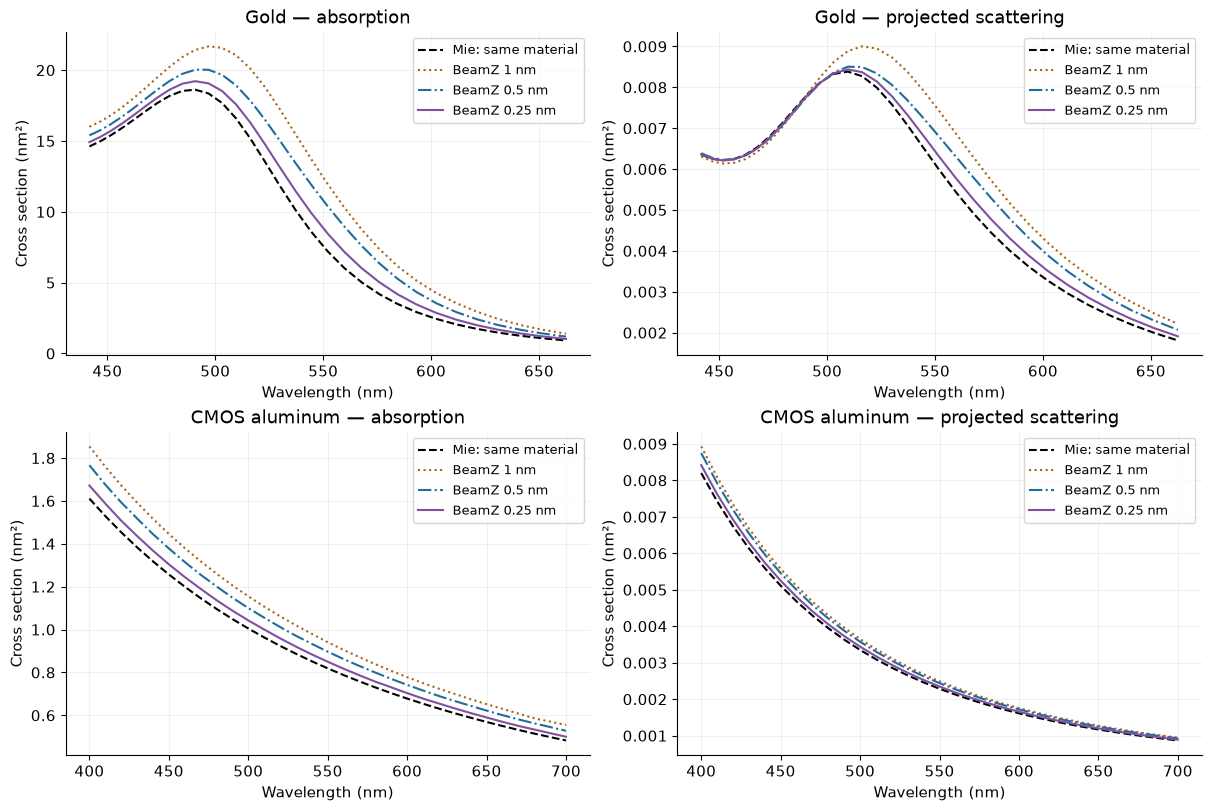

,Material,Mesh (nm),Absorption error (%),Optical-theorem absorption error (%),Projected scattering error (%),Direct array flux vs isolated Mie (%)
2,aluminum,1.00,15.119,27.431,8.922,67.518
1,aluminum,0.50,9.649,15.552,6.689,68.445
0,aluminum,0.25,3.784,6.495,2.647,71.654
5,gold,1.00,29.032,29.949,17.173,49.089
4,gold,0.50,17.802,18.245,10.447,56.532
3,gold,0.25,7.195,7.409,4.063,66.943


In [3]:
fig, axes=plt.subplots(2,2,figsize=(12,8),constrained_layout=True)
for row,name in enumerate(('sphere_gold','aluminum')):
    runs=sorted(((p,r) for p,r in spheres if r['material']==name),key=lambda pr:-pr[1]['dx_nm'])
    for j,(path,r) in enumerate(runs):
        d=np.load(path/'spectra.npz'); wl=d['wavelength_nm']; idx=np.argsort(wl)
        for col,quantity in enumerate(('absorption','scattering')):
            ax=axes[row,col]
            if j==0: ax.plot(wl[idx],d[quantity+'_exact'][idx]*1e18,'k--',label='Mie: same material')
            key='absorption_8' if quantity=='absorption' else 'scattering_projected_8'
            ax.plot(wl[idx],d[key][idx]*1e18,color=COLORS[r['dx_nm']],linestyle={1.0:':',.5:'-.',.25:'-'}[r['dx_nm']],label=f"BeamZ {r['dx_nm']:g} nm")
            ax.set(title=f"{'Gold' if row==0 else 'CMOS aluminum'} — {'projected scattering' if col else 'absorption'}",xlabel='Wavelength (nm)',ylabel='Cross section (nm²)')
            ax.legend(fontsize=9)
fig.savefig(OUT/'sphere_spectra.png',dpi=160)
plt.show()
rows=[]
for path,r in spheres:
    s=next(v for v in r['surfaces'] if v['half_nm']==8)
    rows.append({'Material':r['material'].replace('sphere_',''),'Mesh (nm)':r['dx_nm'],'Absorption error (%)':100*s['absorption_relative_max'],'Optical-theorem absorption error (%)':100*s['absorption_optical_theorem_relative_max'],'Projected scattering error (%)':100*s['scattering_projected_relative_max'],'Direct array flux vs isolated Mie (%)':100*s['scattering_relative_max']})
sphere_table=pd.DataFrame(rows).sort_values(['Material','Mesh (nm)'],ascending=[True,False])
display(sphere_table.round(3))
sphere_table.to_csv(OUT/'sphere_summary.csv',index=False)


The direct periodic-array scattering flux is **not the isolated-particle scattering cross section**. For a subdiffractive square electric-dipole array, the ratio of power per cell to isolated-dipole power with the same moment is `3 λ² / (4π A)`. This follows from the array reflection amplitude `r = ikα / (2A)` and isolated dipole radiation; see [Arslan et al., electric-dipole array formulas](https://advanced.onlinelibrary.wiley.com/doi/10.1002/adma.202105868). At 530 nm and the 0.5 nm run's actual period, the predicted ratio is 0.514; the aluminum simulation gives 0.512. Thus its large difference from isolated Mie is mostly an observable mismatch, not a demonstrated flux bug. Residual differences from the dipole-array prediction remain (up to 25% of its spectral peak for the 0.25 nm gold run), so this does not fully validate the direct flux extraction. The surface-current projection reconstructs free-space radiation from one particle's response; array interaction can still perturb that response, so domain controls remain necessary. Agreement between enclosing surfaces and an analytic-dipole check test the extraction; neither replaces the independent Mie reference. The optical-theorem column independently obtains extinction from the forward-scattered amplitude, then subtracts projected scattering. Its disagreement with surface-flux absorption, particularly for aluminum, is an additional extraction/discretization uncertainty rather than a passed validation.

In [4]:
from metal_far_field import validate_dipole
print('Analytical dipole relative errors, 20 and 40 surface cells:',validate_dipole())
controls=[]
for path,r in all_spheres:
    if (path,r) in spheres: continue
    matching=next(p for p,b in spheres if b['material']==r['material'] and b['dx_nm']==r['dx_nm'])
    a,b=np.load(path/'spectra.npz'),np.load(matching/'spectra.npz')
    controls.append({'Boundary':r['lateral_boundary'],'Mesh (nm)':r['dx_nm'],'Actual lateral span (nm)':r['actual_period_nm'],'Absorption change / Mie peak (%)':100*max(abs(a['absorption_8']-b['absorption_8']))/max(b['absorption_exact']),'Scattering change / Mie peak (%)':100*max(abs(a['scattering_projected_8']-b['scattering_projected_8']))/max(b['scattering_exact'])})
display(pd.DataFrame(controls).round(4))
pd.DataFrame(controls).to_csv(OUT/'domain_summary.csv',index=False)
checks=[]
for path,r in spheres:
    d=np.load(path/'spectra.npz')
    checks.append({'Material':r['material'],'Mesh (nm)':r['dx_nm'],'Absorption surface difference / Mie peak (%)':100*max(abs(d['absorption_6']-d['absorption_8']))/max(d['absorption_exact']),'Scattering surface difference / Mie peak (%)':100*max(abs(d['scattering_projected_6']-d['scattering_projected_8']))/max(d['scattering_exact'])})
display(pd.DataFrame(checks).round(5))


Analytical dipole relative errors, 20 and 40 surface cells: {'radiated_power': [0.0012256108766890428, 0.000306321217973915], 'optical_theorem': [0.0006122922205258341, 0.00015306681080184958]}


,Boundary,Mesh (nm),Actual lateral span (nm),Absorption change / Mie peak (%),Scattering change / Mie peak (%)
0,periodic,0.5,265.1167,0.0367,0.0338
1,cpml,1.0,902.3918,0.0167,0.0173


,Material,Mesh (nm),Absorption surface difference / Mie peak (%),Scattering surface difference / Mie peak (%)
0,aluminum,0.25,0.06964,0.00330
1,aluminum,0.50,0.09994,0.00208
2,aluminum,1.00,0.04130,0.00897
3,sphere_gold,0.25,0.01690,0.00756
4,sphere_gold,0.50,0.00590,0.00399
5,sphere_gold,1.00,0.00766,0.00658


## 3. Metasurface reflection: the remaining discrepancy

The full dashed curves are approximate readings of Tidy3D's published plot. BeamZ tests three antenna lengths; colored markers show only computed cases, without interpolating uncomputed lengths. At 2.5 nm, only the planar control and central antenna were rerun with the final outgoing-field measurement, so the fine result appears in the power panel only. Relative phase is anchored to the 40 nm antenna separately for each complete three-point series.

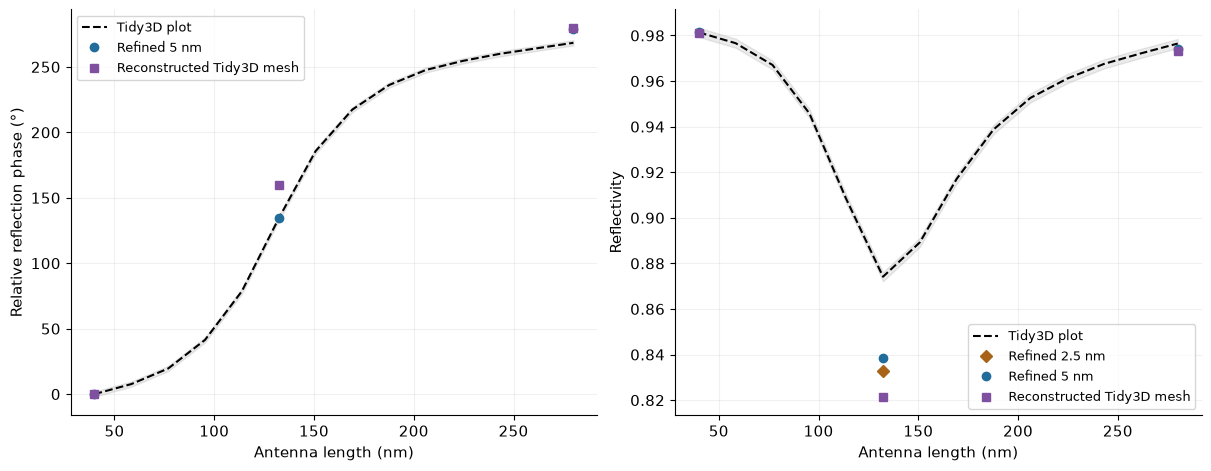

,Mesh,Length (nm),BeamZ R (%),"Tidy3D R (%, approx)",R difference (pp),Relative phase (°),Phase difference (°)
4,Reconstructed Tidy3D mesh,40.000,98.106,98.138,-0.032,0.0,0.0
1,Refined 5 nm,40.000,98.135,98.138,-0.004,0.0,0.0
5,Reconstructed Tidy3D mesh,132.308,82.150,87.415,-5.266,159.731,25.529
0,Refined 2.5 nm,132.308,83.265,87.415,-4.150,—,—
2,Refined 5 nm,132.308,83.869,87.415,-3.546,134.705,0.503
6,Reconstructed Tidy3D mesh,280.000,97.335,97.646,-0.311,279.895,11.49
3,Refined 5 nm,280.000,97.417,97.646,-0.229,279.051,10.646


In [5]:
published=pd.DataFrame(json.loads((DATA/'metasurface_digitized.json').read_text())['runs'])
series={}
for path,r in outgoing:
    key='Reconstructed Tidy3D mesh' if r['mesh']=='reference' else f"Refined {r['dx_nm']:g} nm"
    series.setdefault(key,[]).extend(v for v in r['runs'] if v['length_nm']>0)
fig,axes=plt.subplots(1,2,figsize=(12,4.6),constrained_layout=True)
axes[0].plot(published.length_nm,published.phase_degrees,'k--',label='Tidy3D plot')
axes[1].plot(published.length_nm,published.reflectivity,'k--',label='Tidy3D plot')
axes[0].fill_between(published.length_nm,published.phase_degrees-2,published.phase_degrees+2,color='k',alpha=.08)
axes[1].fill_between(published.length_nm,published.reflectivity-.002,published.reflectivity+.002,color='k',alpha=.08)
comparison=[]
styles={'Reconstructed Tidy3D mesh':('#8050a0','s'),'Refined 5 nm':('#216c9b','o'),'Refined 2.5 nm':('#a96318','D')}
for label,values in series.items():
    d=pd.DataFrame(values).sort_values('length_nm'); color,marker=styles[label]
    phases=np.full(len(d),np.nan)
    if len(d)==3:
        phases=np.unwrap(np.angle(d.r_real.to_numpy()+1j*d.r_imag.to_numpy()))*180/np.pi
        phases-=phases[0]
        axes[0].plot(d.length_nm,phases,marker=marker,color=color,label=label,linestyle='none')
    axes[1].plot(d.length_nm,d.r_power,marker=marker,color=color,label=label,linestyle='none')
    for i,(_,v) in enumerate(d.iterrows()):
        target=np.interp(v.length_nm,published.length_nm,published.reflectivity)
        phase_target=np.interp(v.length_nm,published.length_nm,published.phase_degrees)
        comparison.append({'Mesh':label,'Length (nm)':v.length_nm,'BeamZ R (%)':100*v.r_power,'Tidy3D R (%, approx)':100*target,'R difference (pp)':100*(v.r_power-target),'Relative phase (°)':phases[i],'Phase difference (°)':phases[i]-phase_target})
for ax,label in zip(axes,('Relative reflection phase (°)','Reflectivity')):
    ax.set(xlabel='Antenna length (nm)',ylabel=label);ax.legend(fontsize=9)
fig.savefig(OUT/'metasurface_comparison.png',dpi=160)
plt.show()
comparison=pd.DataFrame(comparison).sort_values(['Length (nm)','Mesh'])
display(comparison.round(3).fillna('—'))
comparison.to_csv(OUT/'metasurface_summary.csv',index=False)


## 4. Controls on reflection measurement and metal placement

Removing the antenna leaves an analytically solvable multilayer. Agreement here validates reflected power for this stack, but not the full resonator's near fields. The metal-ownership comparison uses Tidy3D's **client-side point sampler**, not its proprietary server-side subpixel operator. The latter remains an unverified difference. A supplementary CPU run with arithmetic volume averaging gives the same central-cell reflectivity as the GPU diagonal run. The compiled εx/εy/εz arrays and all metal pole-owner arrays are **exactly equal** for those two policies on this reconstructed mesh. Thus switching between these two dielectric policies cannot resolve this particular discrepancy; their shared junction treatment remains untested against the Tidy3D server.

In [6]:
from analyze_metal_reflector import main as analyze_reflector
import contextlib, io
with contextlib.redirect_stdout(io.StringIO()): analyze_reflector()
checks=pd.DataFrame(json.loads((OUT/'reflector_checks.json').read_text()))
planar=checks.query("measurement == 'above_source_native_power' and length_nm == 0")
planar_table=planar[['mesh','dx_nm','reflectivity','R_exact','R_error_pp','phase_error_degrees']].copy()
planar_table[['reflectivity','R_exact']]*=100
planar_table=planar_table.rename(columns={'mesh':'Mesh','dx_nm':'Nominal spacing (nm)','reflectivity':'BeamZ R (%)','R_exact':'Exact R (%)','R_error_pp':'R error (pp)','phase_error_degrees':'Absolute phase error (°)'})
display(planar_table.reset_index(drop=True).round(5))
print('Largest adjacent-plane power difference (pp):',checks.query("measurement == 'above_source_native_power'").R_planes_difference_pp.abs().max())
display(pd.DataFrame(json.loads((OUT/'metal_point_ownership.json').read_text())))
print('Maximum diagonal-versus-volume coefficient difference:',max(json.loads((OUT/'dielectric_volume_coefficients.json').read_text()).values()))
volume_report=json.loads(next((OUT/'diagnostics/dielectric_volume_cpu').glob('reflector-*/report.json')).read_text())
print('Supplementary CPU volume-averaging reflectivity:',volume_report['runs'][0]['r_power'])


,Mesh,Nominal spacing (nm),BeamZ R (%),Exact R (%),R error (pp),Absolute phase error (°)
0,refined,2.5,98.45145,98.46011,-0.00865,1.45415
1,refined,5.0,98.44386,98.46011,-0.01625,2.94523
2,reference,7.5,98.46965,98.46011,0.00954,5.25601


Largest adjacent-plane power difference (pp): 0.0011708683492317462


,component,beamz_count,tidy3d_point_count,mismatch_count
0,Ex,10800,10800,0
1,Ey,10800,10800,0
2,Ez,11424,11424,0


Maximum diagonal-versus-volume coefficient difference: 0.0
Supplementary CPU volume-averaging reflectivity: 0.8214954722325783


## 5. Junction treatment, independent loss, and grid placement

The fixed-metal-mask junction variant alters only nonmetal-owned supports containing metal and two dielectrics. It excludes the metal fraction and renormalizes the dielectric fractions. Here all affected components are tangential to the remaining dielectric interface; no Ez support is changed. The variant moves reflectivity by **−0.023 percentage points** on the reconstructed mesh and **−0.117 points** at 5 nm. It does not close the Tidy3D gap.

Absorption is independently integrated from **native metal E samples**, using the ADE's discrete frequency response and staggered support volumes. Native E/H flux through planes above and below the device provides the local energy check, including spatially varying near fields. All five cases close the local balance within **0.0001 percentage points**. At 5 nm, the baseline absorbs **16.126%**, and global R+T+A also closes within **0.0004 points**. This clears loss extraction for this resonator; it does not certify continuum convergence or resolve the aluminum sphere.

[Derivation, assumptions, and GPU reproduction](../../docs/reviews/metal-benchmarks/junction-loss/README.md). The global residual uses outgoing reflection and the empty-run incident reference; the local residual uses the net native flux entering the device. They are intentionally separate measurements.

In [7]:
from analyze_metal_junction_loss import main as analyze_junction
with contextlib.redirect_stdout(io.StringIO()):
    analyze_junction()
junction = pd.read_csv(OUT / 'junction_loss_summary.csv')
display(junction.drop(columns=['max_native_electric_drift']).round(7))
print('Maximum absolute local energy residual (percentage points):',
      junction.native_balance_residual_pp.abs().max())


,variant,mesh,dx_nm,length_nm,reflectivity_percent,material_absorption_percent,native_transmission_percent,native_balance_residual_pp,global_balance_residual_pp,junction_candidate_sites,changed_dielectric_sites
0,baseline,refined,5,132.307692,83.869152,16.126130,0.004370,3.260000e-05,0.000350,38,0
1,baseline,reference,graded,0.000000,98.469652,1.574481,0.005394,5.300000e-06,-0.049508,0,0
2,baseline,reference,graded,132.307692,82.149551,17.700278,0.007737,4.580000e-05,0.142461,29,0
3,polarized,refined,5,132.307692,83.752078,16.243504,0.004282,2.000000e-07,0.000137,38,38
4,polarized,reference,graded,132.307692,82.126292,17.764218,0.007686,6.630000e-05,0.101832,29,29


Maximum absolute local energy residual (percentage points): 6.632950283746997e-05


A rigid translation leaves the continuum reflectivity unchanged but moves the geometry relative to the Yee samples. The following controls translate all layers vertically or only the antenna laterally, maintaining its physical dimensions. Their changes quantify **grid-registration sensitivity**, not corrections chosen to match Tidy3D. A smaller change on refinement is useful evidence of convergence, but two registrations do not bound the full discretization error.

,dx_nm,xy_shift_nm,z_shift_nm,reflectivity_percent,change_from_unshifted_pp,max_native_electric_drift
0,5.0,0.000,-1.25,83.957744,0.088593,0.000000
1,5.0,0.000,1.25,83.653802,-0.215350,0.000000
2,2.5,0.625,0.00,82.281302,-0.983977,0.000000
3,5.0,1.250,0.00,82.333182,-1.535969,0.000001


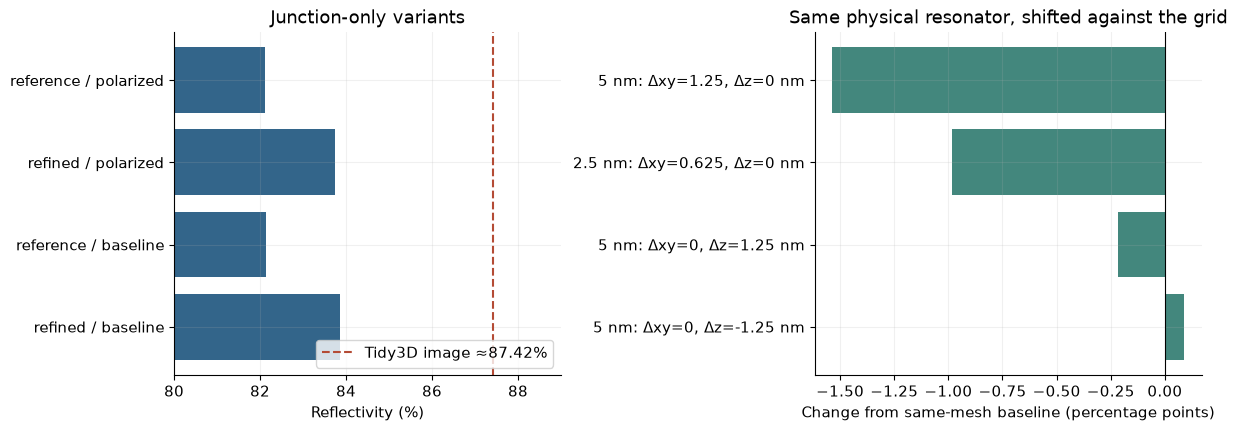

In [8]:
registration = pd.read_csv(OUT / 'registration_summary.csv')
display(registration.round(6))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
resonator = junction[junction.length_nm > 0]
labels = [f"{r.mesh} / {r.variant}" for r in resonator.itertuples()]
axes[0].barh(labels, resonator.reflectivity_percent, color='#33658A')
axes[0].axvline(87.41538462, color='#B44B35', linestyle='--', label='Tidy3D image ≈87.42%')
axes[0].set_xlim(80, 89)
axes[0].set_xlabel('Reflectivity (%)')
axes[0].set_title('Junction-only variants')
axes[0].legend(loc='lower right')
labels = [f"{r.dx_nm:g} nm: Δxy={r.xy_shift_nm:g}, Δz={r.z_shift_nm:g} nm" for r in registration.itertuples()]
axes[1].barh(labels, registration.change_from_unshifted_pp, color='#43877D')
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_xlabel('Change from same-mesh baseline (percentage points)')
axes[1].set_title('Same physical resonator, shifted against the grid')
plt.show()


## 6. Independent Meep control: boundary ownership explains the uniform-grid gap

A separate 10 nm uniform-grid control uses the same Drude model in Meep 1.34.0 (CPU) and BeamZ (RTX3090). Its complex permittivity matches the saved gold model exactly at 850 nm; away from 850 nm it is a different material fit. Both solvers use periodic lateral boundaries, a 300 fs acquisition, and staircasing for **all** interfaces. This deliberately differs from the production dielectric-averaging default.

The coefficient audit finds 372 Ex and 390 Ey sites with different assignments, all on the upper box faces at z=50 and 80 nm. Ez agrees. BeamZ's boxes are half-open; Meep includes these upper faces. Replacing only those effective coefficients and metal-pole supports with Meep's assignments removes almost all the reflection difference. This is a controlled discretization comparison, not a material fit to the target output. It does **not** establish the proprietary Tidy3D server's boundary convention or explain the CMOS discrepancy by itself.

In [9]:
FOLLOWUP = ROOT / 'docs/reviews/cmos-parity-followup'
matched_rows = []
for solver, folder, label in [
    ('Meep', 'meep/dx10-length132.308', 'Meep box ownership'),
    ('BeamZ', 'beamz/dx10-length132.308', 'Half-open box ownership'),
    ('BeamZ', 'beamz/dx10-length132.308-meep-ownership', 'Meep box ownership'),
]:
    report = json.loads((FOLLOWUP / folder / 'report.json').read_text())
    matched_rows.append({'Solver': solver, 'Boundary convention': label,
                         'Reflection (%)': 100 * report['reflection_850'],
                         'Transmission (%)': 100 * report['transmission_850']})
matched = pd.DataFrame(matched_rows)
display(matched.round(5))
print('Matched-ownership reflection difference (percentage points):',
      round(matched.iloc[2]['Reflection (%)'] - matched.iloc[0]['Reflection (%)'], 5))
print('Reproduce with scripts/validation/meep_metal_crosscheck.py and beamz_meep_metal_crosscheck.py; see the follow-up report for commands.')

,Solver,Boundary convention,Reflection (%),Transmission (%)
0,Meep,Meep box ownership,86.91292,0.00329
1,BeamZ,Half-open box ownership,82.60129,0.00355
2,BeamZ,Meep box ownership,86.90084,0.00329


Matched-ownership reflection difference (percentage points): -0.01208
Reproduce with scripts/validation/meep_metal_crosscheck.py and beamz_meep_metal_crosscheck.py; see the follow-up report for commands.


The matched result agrees at 850 nm to about 0.012 percentage points. Across the 41-frequency common-Drude spectrum, differences still reach 0.412 points (RMS 0.204 points), so the central agreement is not a broadband convergence certificate. The original multi-pole, graded-grid Tidy3D comparison above remains a separate test. In particular, neither energy conservation nor a single grid-refinement sequence identifies interface ownership automatically.

The accompanying full-CMOS control changes dielectric averaging from diagonal polarized to volume averaging; the largest central-efficiency change is only 0.011 percentage points. Evaluating the same complex dielectric response as epsilon/conductivity at 450 nm reproduces the broadband blue efficiency within 0.0008 points. See [the CMOS parity follow-up](../../docs/reviews/cmos-parity-followup/README.md) for the reference-mesh test and remaining limitations.

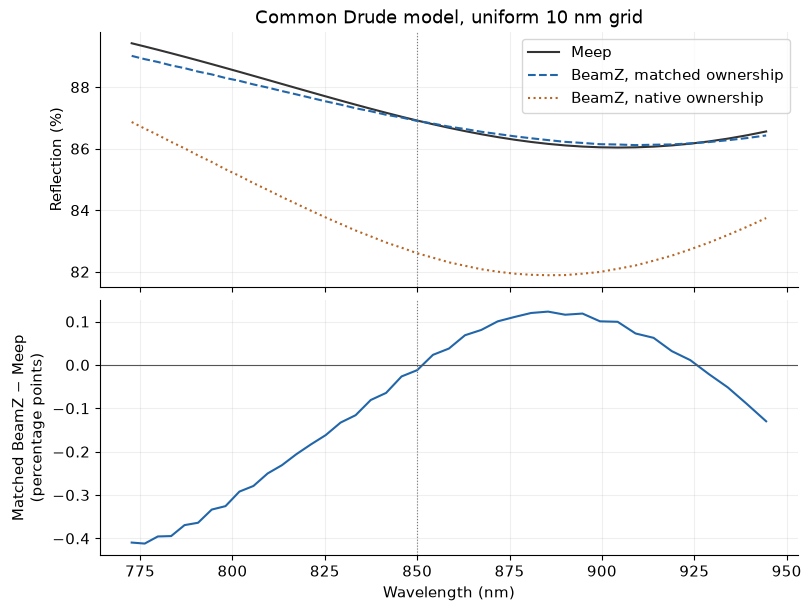

41-frequency residual: max 0.412 pp, RMS 0.204 pp


In [10]:
meep_spectrum = np.load(FOLLOWUP / "meep/dx10-length132.308/spectra.npz")
beamz_spectrum = np.load(FOLLOWUP / "beamz/dx10-length132.308-meep-ownership/spectra.npz")
native_spectrum = np.load(FOLLOWUP / "beamz/dx10-length132.308/spectra.npz")
frequency = meep_spectrum["frequency_hz"]
for spectrum in (beamz_spectrum, native_spectrum):
    np.testing.assert_allclose(spectrum["frequency_hz"], frequency, rtol=1e-12)
wavelength_nm = 299792458e9 / frequency
order = np.argsort(wavelength_nm)
fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True, layout="constrained")
for spectrum, label, color, style in (
    (meep_spectrum, "Meep", "#333333", "-"),
    (beamz_spectrum, "BeamZ, matched ownership", "#2266aa", "--"),
    (native_spectrum, "BeamZ, native ownership", "#b76524", ":"),
):
    axes[0].plot(wavelength_nm[order], 100*spectrum["reflection"][order],
                 label=label, color=color, linestyle=style)
delta = 100*(beamz_spectrum["reflection"] - meep_spectrum["reflection"])
axes[1].plot(wavelength_nm[order], delta[order], color="#2266aa")
axes[1].axhline(0, color="#555555", linewidth=0.8)
for ax in axes:
    ax.axvline(850, color="#777777", linestyle=":", linewidth=0.8)
    ax.grid(alpha=0.2)
axes[0].set(ylabel="Reflection (%)", title="Common Drude model, uniform 10 nm grid")
axes[0].legend()
axes[1].set(xlabel="Wavelength (nm)", ylabel="Matched BeamZ − Meep\n(percentage points)")
fig.savefig(FOLLOWUP / "meep_ownership_spectrum.png", dpi=160)
plt.show()
print(f"41-frequency residual: max {abs(delta).max():.3f} pp, RMS {np.sqrt(np.mean(delta**2)):.3f} pp")

## 7. A separate CPML default problem

The default CPML frequency-shift parameter scales with 1/dt. With sub-nanometer interior cells and much coarser outer cells, the empty-domain illumination becomes strongly reflected. Setting `alpha_max=0` reduces the reflected-field amplitude to roughly 0.17%. Invalid initial sphere runs are archived under `diagnostics/` and excluded from the convergence series.

This is a demonstrated issue for this graded-mesh CPML configuration. **It does not explain the original CMOS mismatch**, whose absorber does not use this CPML default. No global solver default was changed in this benchmark work.

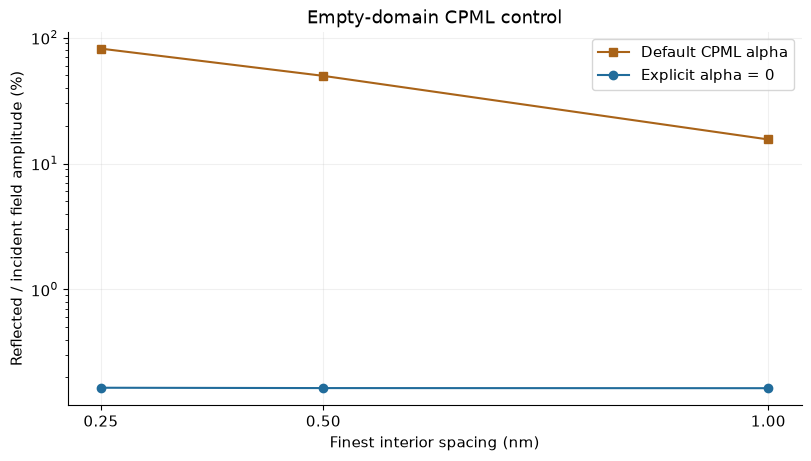

In [11]:
pml=pd.DataFrame(json.loads((OUT/'pml_incident_check.json').read_text()))
fig,ax=plt.subplots(figsize=(8,4.5),constrained_layout=True)
for zero,label,color,marker in [(False,'Default CPML alpha','#a96318','s'),(True,'Explicit alpha = 0','#216c9b','o')]:
    d=pml[pml.alpha_max.eq(0) if zero else pml.alpha_max.isna()].sort_values('dx_nm')
    ax.plot(d.dx_nm,100*d.reflection_amplitude,marker=marker,color=color,label=label)
ax.set(xlabel='Finest interior spacing (nm)',ylabel='Reflected / incident field amplitude (%)',title='Empty-domain CPML control',yscale='log',xticks=[.25,.5,1]);ax.legend()
fig.savefig(OUT/'pml_illumination.png',dpi=160)
plt.show()


## Reproduce and inspect

The notebook loads committed numerical results and recomputes lightweight checks and plots. It does not launch long GPU jobs. Use the commands in the [report](../../docs/reviews/metal-benchmarks/README.md) for the RTX3090 simulations. `miepython==3.3.0` is an optional independent-reference dependency; Tidy3D 2.9.0 is needed only to reconstruct grids and point samples locally. Raw surface DFT arrays are large local intermediates and are regenerated by the runner; spectra and reports are committed.

The gold-resonator material-loss check below now passes; the separate aluminum-sphere optical-theorem/flux disagreement remains open. The junction variant does not close the resonator gap. Grid registration still changes its reflected power, so metal edge representation and convergence of the resonant field remain concerns. These tests do not establish that BeamZ and Tidy3D use the same effective interface operator, or identify a shared cause of the CMOS red/blue discrepancy. No production solver defaults were changed by these diagnostics.
